# V6: EEGNet cho phân loại P300 đơn trial

Phân loại **standard vs target** trực tiếp từ epoch thô (128 kênh × 301 mẫu, 250 Hz), không cần trích đặc trưng như V4/V5.

- Mô hình: **EEGNet-8,2** (Lawhern et al., 2018), code tại `src/dl/train_eegnet.py` (PyTorch thuần).
- Đánh giá: cùng cách chia và bộ chỉ số với V5 (`GroupKFold` theo người, hoặc `StratifiedKFold` khi chỉ có 1 người) để so sánh trực tiếp.
- Dữ liệu: nếu có epoch thật trong `derivatives/v1/epochs/` (và đã cài `mne`) thì dùng dữ liệu thật; nếu không, notebook tự chuyển sang **dữ liệu mô phỏng** cùng định dạng để chạy thử.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import (average_precision_score, precision_recall_curve,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import train_test_split

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from config import FIG_DIR, RANDOM_SEED, SFREQ, TABLE_DIR, TMIN
from src.dl.train_eegnet import (EEGNet, compute_metrics, count_parameters,
                                 cross_validate, get_device, load_real_dataset,
                                 make_synthetic_dataset, predict_proba,
                                 real_data_available, saliency_map, summarize,
                                 train_eegnet)

DEVICE = get_device()
print(f"PyTorch {torch.__version__}, thiết bị: {DEVICE}"
      + (f" ({torch.cuda.get_device_name(0)})" if DEVICE.type == "cuda" else ""))

PyTorch 2.7.1+cu118, thiết bị: cuda (NVIDIA GeForce RTX 4060)


## 1. Tải dữ liệu

`DATA_MODE`:
- `"auto"`: dùng epoch thật của `REAL_SUBJECTS` nếu có, không thì dùng dữ liệu mô phỏng.
- `"real"` / `"synthetic"`: ép dùng một loại.

**Dữ liệu mô phỏng** (`make_synthetic_dataset`): 5 người × 400 trial, khoảng 12% target. Mỗi trial có N1/P2 thị giác, nhiễu 1/f tương quan giữa các kênh và alpha ~10 Hz; trial target có thêm P300 (~350–450 ms, độ trễ dao động) phân bố quanh "vùng đỉnh" (quanh kênh 80). SNR cố ý để thấp (P300 ~3 µV, nhiễu ~10 µV) để bài toán không quá dễ. Kết quả trên dữ liệu này **chỉ để kiểm tra pipeline chạy đúng**, không so sánh được với số liệu thật của V5.

In [2]:
DATA_MODE = "auto"
REAL_SUBJECTS = ["sub-01"]          # None = toàn bộ 39 người hợp lệ

use_real = DATA_MODE == "real" or (DATA_MODE == "auto" and real_data_available(REAL_SUBJECTS))
if use_real:
    X, y, groups = load_real_dataset(REAL_SUBJECTS)
    DATA_TAG = "real"
else:
    X, y, groups = make_synthetic_dataset(n_subjects=5, n_trials=400)
    DATA_TAG = "synthetic"

times = TMIN + np.arange(X.shape[2]) / SFREQ
print(f"Dữ liệu: {DATA_TAG}")
print(f"X: {X.shape} (trial, kênh, mẫu), đơn vị µV")
print(f"Số người: {len(np.unique(groups))}")
print(f"Target: {int(y.sum())} / {len(y)} trial ({y.mean():.1%})")

Dữ liệu: synthetic
X: (2000, 128, 301) (trial, kênh, mẫu), đơn vị µV
Số người: 5
Target: 267 / 2000 trial (13.4%)


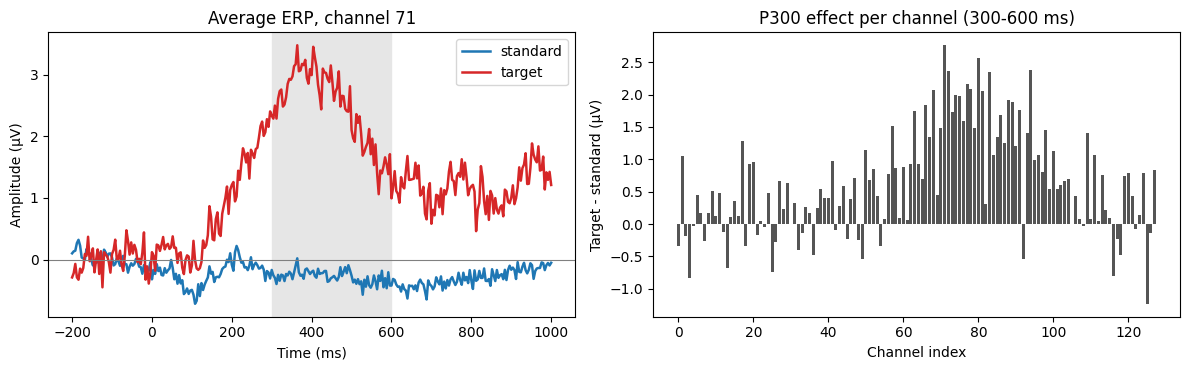

In [3]:
# Kiểm tra nhanh: ERP trung bình target vs standard ở kênh có hiệu ứng P300 mạnh nhất (300-600 ms)
win = (times >= 0.3) & (times <= 0.6)
diff = X[y == 1][:, :, win].mean((0, 2)) - X[y == 0][:, :, win].mean((0, 2))
best_ch = int(np.argmax(diff))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
ax = axes[0]
for label, color, name in [(0, "#1f77b4", "standard"), (1, "#d62728", "target")]:
    ax.plot(times * 1000, X[y == label, best_ch].mean(0), color=color, lw=1.8, label=name)
ax.axvspan(300, 600, color="0.9", zorder=0)
ax.axhline(0, color="0.5", lw=0.8)
ax.set(xlabel="Time (ms)", ylabel="Amplitude (µV)", title=f"Average ERP, channel {best_ch}")
ax.legend()

axes[1].bar(np.arange(len(diff)), diff, color="#555555")
axes[1].set(xlabel="Channel index", ylabel="Target - standard (µV)",
            title="P300 effect per channel (300-600 ms)")
fig.tight_layout()
plt.show()

## 2. Kiến trúc EEGNet

| Khối | Lớp | Ý nghĩa |
|---|---|---|
| 1 | Conv2D (1 × 125), F1 = 8 | Bộ lọc thời gian dài 0,5 s, học các dải tần |
| 1 | DepthwiseConv2D (128 × 1), D = 2, max-norm 1 | Bộ lọc không gian cho từng bộ lọc thời gian (giống CSP/xDAWN) |
| 1 | BN → ELU → AvgPool (1 × 4) → Dropout 0,5 | Giảm mẫu 250 → 62,5 Hz |
| 2 | SeparableConv2D (1 × 16), F2 = 16 | Tổng hợp thời gian ~250 ms |
| 2 | BN → ELU → AvgPool (1 × 8) → Dropout 0,5 | |
| Ra | Flatten → Linear (2 lớp), max-norm 0,25 | |

Mất cân bằng lớp được xử lý bằng **cross-entropy có trọng số lớp** (tương đương `class_weight="balanced"` ở V5).

In [4]:
model = EEGNet(n_channels=X.shape[1], n_times=X.shape[2])
print(model)
print(f"\nSố tham số huấn luyện: {count_parameters(model):,}")

x = torch.zeros(1, 1, X.shape[1], X.shape[2])
for name, layer in [("temporal", model.temporal), ("spatial", model.spatial),
                    ("block1_rest", model.block1_rest), ("block2", model.block2)]:
    x = layer(x)
    print(f"{name:12s} -> {tuple(x.shape)}")

EEGNet(
  (temporal): Sequential(
    (0): Conv2d(1, 8, kernel_size=(1, 125), stride=(1, 1), padding=(0, 62), bias=False)
    (1): BatchNorm2d(8, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  )
  (spatial): Conv2d(8, 16, kernel_size=(128, 1), stride=(1, 1), groups=8, bias=False)
  (block1_rest): Sequential(
    (0): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (1): ELU(alpha=1.0)
    (2): AvgPool2d(kernel_size=(1, 4), stride=(1, 4), padding=0)
    (3): Dropout(p=0.5, inplace=False)
  )
  (block2): Sequential(
    (0): Conv2d(16, 16, kernel_size=(1, 16), stride=(1, 1), padding=(0, 8), groups=16, bias=False)
    (1): Conv2d(16, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (3): ELU(alpha=1.0)
    (4): AvgPool2d(kernel_size=(1, 8), stride=(1, 8), padding=0)
    (5): Dropout(p=0.5, inplace=False)
  )
  (classifier): Linear(in_features=

## 3. Huấn luyện thử trên một lần chia

Giữ 20% trial làm tập test, phần còn lại tách 15% làm validation cho early stopping (dừng khi val loss không giảm sau 15 epoch). Bước này để xem đường cong học trước khi chạy cross-validation.

In [5]:
EPOCHS, PATIENCE, BATCH_SIZE, LR = 100, 15, 64, 1e-3

idx = np.arange(len(y))
tr_idx, te_idx = train_test_split(idx, test_size=0.2, stratify=y, random_state=RANDOM_SEED)
tr_idx, va_idx = train_test_split(tr_idx, test_size=0.15, stratify=y[tr_idx], random_state=RANDOM_SEED)

model, history, scale = train_eegnet(X[tr_idx], y[tr_idx], X[va_idx], y[va_idx],
                                     epochs=EPOCHS, patience=PATIENCE, batch_size=BATCH_SIZE,
                                     lr=LR, device=DEVICE, verbose=True)
probs_te = predict_proba(model, X[te_idx], scale)
pd.Series(compute_metrics(y[te_idx], probs_te)).round(3).to_frame("hold-out test")

  epoch   0  train 0.6987  val 0.6779  AUC 0.674  BAcc 0.617


  epoch  10  train 0.1699  val 0.1909  AUC 0.988  BAcc 0.954


  epoch  20  train 0.0777  val 0.1064  AUC 0.995  BAcc 0.984


  epoch  30  train 0.0491  val 0.0584  AUC 1.000  BAcc 0.984


  epoch  40  train 0.0335  val 0.0407  AUC 1.000  BAcc 1.000


  epoch  50  train 0.0181  val 0.0438  AUC 1.000  BAcc 0.984


... (2 outputs left out)

  epoch  80  train 0.0110  val 0.0309  AUC 1.000  BAcc 0.984


  epoch  90  train 0.0075  val 0.0365  AUC 1.000  BAcc 0.969


  early stop ở epoch 98 (tốt nhất: epoch 83)


,hold-out test
balanced_accuracy,0.991
roc_auc,1.000
pr_auc,1.000
f1_macro,0.995
f1_target,0.990
sensitivity,0.981
specificity,1.000


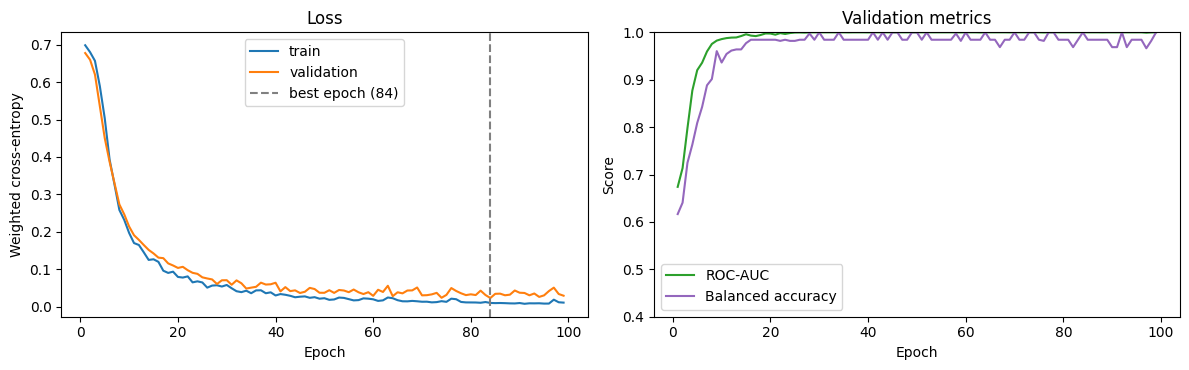

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
ep = np.arange(1, len(history["train_loss"]) + 1)
axes[0].plot(ep, history["train_loss"], label="train", color="#1f77b4")
axes[0].plot(ep, history["val_loss"], label="validation", color="#ff7f0e")
best_ep = int(np.argmin(history["val_loss"])) + 1
axes[0].axvline(best_ep, ls="--", color="0.5", label=f"best epoch ({best_ep})")
axes[0].set(xlabel="Epoch", ylabel="Weighted cross-entropy", title="Loss")
axes[0].legend()
axes[1].plot(ep, history["val_auc"], label="ROC-AUC", color="#2ca02c")
axes[1].plot(ep, history["val_bacc"], label="Balanced accuracy", color="#9467bd")
axes[1].set(xlabel="Epoch", ylabel="Score", title="Validation metrics", ylim=(0.4, 1.0))
axes[1].legend()
fig.tight_layout()
plt.show()

## 4. Cross-validation (giống V5)

- ≥ 5 người → `GroupKFold(5)`: người ở tập test không xuất hiện khi huấn luyện (đánh giá liên người, không rò rỉ).
- 1 người → `StratifiedKFold(5)`.

Trong mỗi fold: tách 15% tập train làm validation cho early stopping; hệ số chuẩn hóa tính trên tập train của fold.

In [7]:
fold_df, oof_probs, histories = cross_validate(X, y, groups, n_splits=5, epochs=EPOCHS,
                                               patience=PATIENCE, batch_size=BATCH_SIZE, lr=LR,
                                               device=DEVICE)
fold_df.round(3)

GroupKFold, 5 fold, 2000 trial, 5 người


Fold 1: AUC 0.757  BAcc 0.655  PR-AUC 0.318  (100 epoch, 87s)


Fold 2: AUC 0.784  BAcc 0.670  PR-AUC 0.410  (96 epoch, 83s)


Fold 3: AUC 0.853  BAcc 0.711  PR-AUC 0.492  (100 epoch, 88s)


Fold 4: AUC 0.742  BAcc 0.667  PR-AUC 0.381  (91 epoch, 83s)


Fold 5: AUC 0.818  BAcc 0.689  PR-AUC 0.449  (100 epoch, 88s)


,fold,n_test,epochs_run,balanced_accuracy,roc_auc,pr_auc,f1_macro,f1_target,sensitivity,specificity
0,1,400,100,0.655,0.757,0.318,0.486,0.315,0.808,0.503
1,2,400,96,0.670,0.784,0.410,0.514,0.341,0.800,0.539
2,3,400,100,0.711,0.853,0.492,0.496,0.348,0.942,0.480
3,4,400,91,0.667,0.742,0.381,0.549,0.338,0.692,0.641
4,5,400,100,0.689,0.818,0.449,0.492,0.352,0.911,0.468


In [8]:
summary = summarize("EEGNet", fold_df, y, oof_probs)
summary_df = pd.DataFrame([summary])

TABLE_DIR.mkdir(parents=True, exist_ok=True)
out_csv = TABLE_DIR / f"eegnet_metrics_{DATA_TAG}.csv"
summary_df.to_csv(out_csv, index=False)
print(f"Đã lưu: {out_csv.relative_to(ROOT)}")

cols = ["model", "balanced_accuracy_mean", "roc_auc_mean", "pr_auc_mean",
        "f1_macro_mean", "sensitivity_mean", "specificity_mean"]
baseline_csv = TABLE_DIR / "baseline_metrics.csv"
table = summary_df[cols]
if baseline_csv.exists():
    table = pd.concat([pd.read_csv(baseline_csv)[cols], table], ignore_index=True)
if DATA_TAG != "real":
    print("Lưu ý: baseline V5 tính trên đặc trưng của dữ liệu thật; dòng EEGNet ở đây là dữ liệu mô phỏng, "
          "chỉ để tham khảo định dạng, KHÔNG so sánh trực tiếp.")
table.set_index("model").round(3)

Đã lưu: results\tables\eegnet_metrics_real.csv


model,balanced_accuracy_mean,roc_auc_mean,pr_auc_mean,f1_macro_mean,sensitivity_mean,specificity_mean
Dummy,0.497,0.497,0.134,0.497,0.127,0.867
LDA,0.815,0.947,0.791,0.835,0.659,0.971
Logistic Regression,0.874,0.946,0.791,0.816,0.841,0.908
RBF SVM,0.799,0.946,0.791,0.824,0.625,0.973
Random Forest,0.638,0.907,0.652,0.678,0.289,0.988
EEGNet,0.821,0.890,0.694,0.699,0.823,0.819


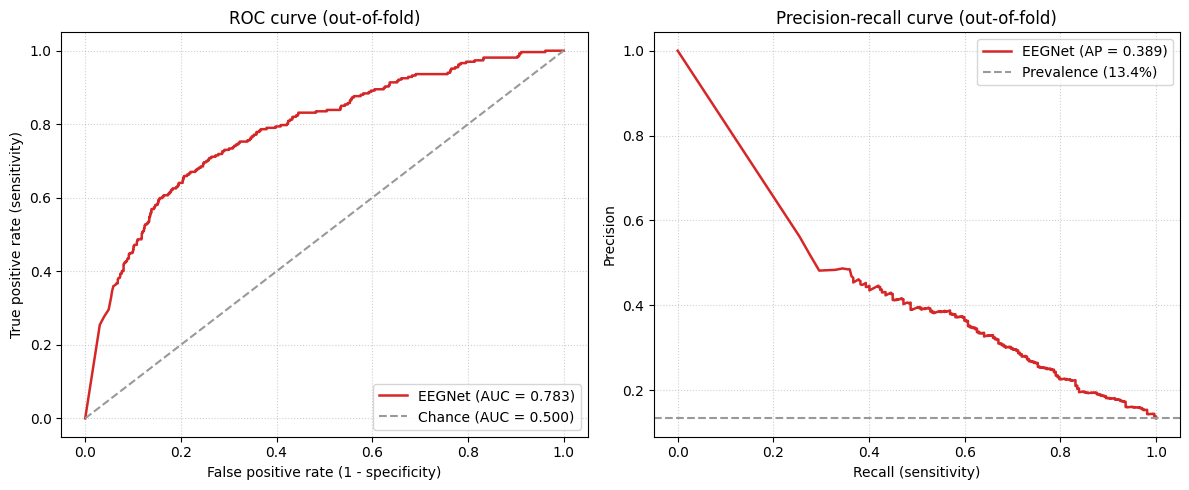

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fpr, tpr, _ = roc_curve(y, oof_probs)
axes[0].plot(fpr, tpr, color="#d62728", lw=1.8, label=f"EEGNet (AUC = {roc_auc_score(y, oof_probs):.3f})")
axes[0].plot([0, 1], [0, 1], "--", color="#999999", label="Chance (AUC = 0.500)")
axes[0].set(xlabel="False positive rate (1 - specificity)", ylabel="True positive rate (sensitivity)",
            title="ROC curve (out-of-fold)")
axes[0].legend(loc="lower right")

prec, rec, _ = precision_recall_curve(y, oof_probs)
axes[1].plot(rec, prec, color="#d62728", lw=1.8, label=f"EEGNet (AP = {average_precision_score(y, oof_probs):.3f})")
axes[1].axhline(y.mean(), ls="--", color="#999999", label=f"Prevalence ({y.mean():.1%})")
axes[1].set(xlabel="Recall (sensitivity)", ylabel="Precision", title="Precision-recall curve (out-of-fold)")
axes[1].legend(loc="upper right")
for ax in axes:
    ax.grid(True, ls=":", alpha=0.6)
fig.tight_layout()

FIG_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(FIG_DIR / f"eegnet_roc_pr_{DATA_TAG}.png", dpi=200, bbox_inches="tight")
plt.show()

## 5. Giải thích mô hình: saliency map

Saliency = |∂ logit(target) / ∂ đầu vào|, lấy trung bình trên các trial target của tập test ở lần chia ở mục 3. Nếu mô hình học đúng P300, độ nhạy sẽ tập trung ở **300–600 ms** và ở các kênh có hiệu ứng P300 mạnh (hình ở mục 1).

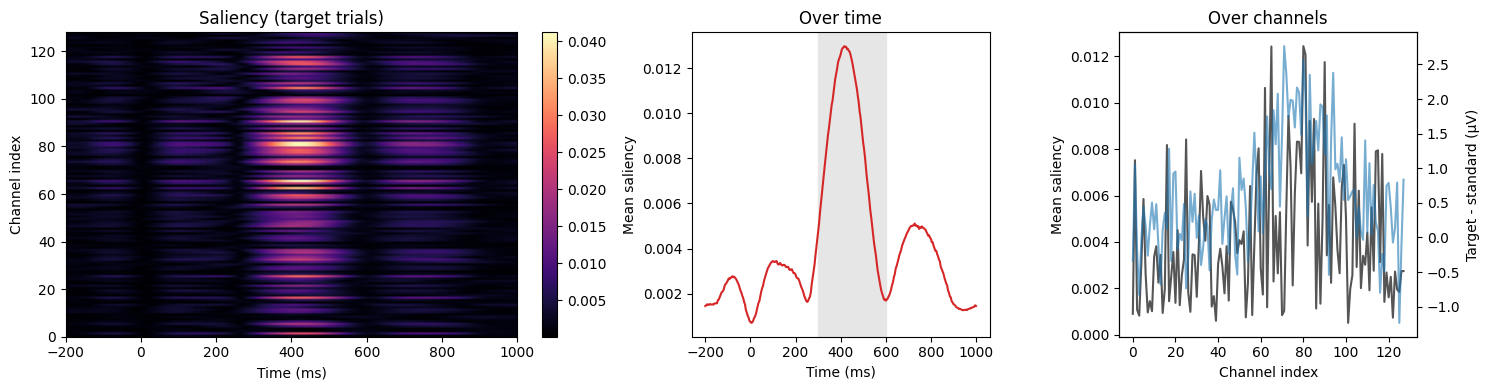

Đỉnh saliency theo thời gian: 416 ms
Tương quan saliency theo kênh với hiệu ứng P300: r = 0.28


In [10]:
sal = saliency_map(model, X[te_idx][y[te_idx] == 1], scale)

fig, axes = plt.subplots(1, 3, figsize=(15, 4), gridspec_kw={"width_ratios": [2, 1.2, 1.2]})
im = axes[0].imshow(sal, aspect="auto", cmap="magma", origin="lower",
                    extent=[times[0] * 1000, times[-1] * 1000, 0, sal.shape[0]])
axes[0].set(xlabel="Time (ms)", ylabel="Channel index", title="Saliency (target trials)")
fig.colorbar(im, ax=axes[0], fraction=0.04)

axes[1].plot(times * 1000, sal.mean(0), color="#d62728")
axes[1].axvspan(300, 600, color="0.9", zorder=0)
axes[1].set(xlabel="Time (ms)", ylabel="Mean saliency", title="Over time")

axes[2].plot(sal.mean(1), color="#555555", label="saliency")
ax2 = axes[2].twinx()
ax2.plot(diff, color="#1f77b4", alpha=0.6, label="P300 effect")
axes[2].set(xlabel="Channel index", ylabel="Mean saliency", title="Over channels")
ax2.set_ylabel("Target - standard (µV)")
fig.tight_layout()
fig.savefig(FIG_DIR / f"eegnet_saliency_{DATA_TAG}.png", dpi=200, bbox_inches="tight")
plt.show()

peak_ms = times[np.argmax(sal.mean(0))] * 1000
r = np.corrcoef(sal.mean(1), diff)[0, 1]
print(f"Đỉnh saliency theo thời gian: {peak_ms:.0f} ms")
print(f"Tương quan saliency theo kênh với hiệu ứng P300: r = {r:.2f}")

## 6. Ghi chú

- Khi có epoch thật: đặt `DATA_MODE = "real"`, `REAL_SUBJECTS = ["sub-01"]` để thử 1 người, hoặc `None` để chạy cả 39 người (21.878 trial, khoảng 3,4 GB float32; cần đủ RAM). Kết quả lưu vào `results/tables/eegnet_metrics_real.csv`, cùng cột với `baseline_metrics.csv` của V5.
- Ngưỡng quyết định đang là 0,5 (giống V5). Do dùng trọng số lớp, mô hình thiên về độ nhạy (sensitivity) cao hơn độ đặc hiệu (specificity).
- Có thể chạy từ dòng lệnh: `python src/dl/train_eegnet.py --synthetic --save` hoặc `python src/dl/train_eegnet.py --subjects sub-01 --save`.